In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

2024-03-01 23:52:05.525882: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-03-01 23:52:05.577039: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-01 23:52:05.577074: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-01 23:52:05.578578: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-03-01 23:52:05.586397: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-03-01 23:52:05.587544: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [3]:
V_width = 1
# reference_times = np.array([0,2,4,6,8,10,12,14,16,18,20]).astype(int)
reference_times = np.linspace(0,20,6).astype(int)
V_E_buffer_array = np.linspace(0,30,16).astype(int)
# V_E_buffer_array = np.arange(20).astype(int)
# V_E_buffer_array = np.array([8]).astype(int)
E_width = 1
N_meta_neurons = 4

N_training_repeats = 10
critic_params = {
    "hidden_dim": 32,
    "embed_dim": 8,
    "layers": 2,
    "activation": "tanh",
}
train_opt_params = {"track_quantities": False, "quiet": True, "iterations": 5}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 1}
mi_measurement_params = {"quiet": True, "batch_size": 500, "N_batches": 500}

train_fraction = 0.5
samp_keep = 1

## trial shuffling options - trial shuffling options will only work with natural scenes stims.
shuffle_type = None  # do not shuffle
# shuffle_type = 'trial'  # shuffle trial index for each cell
# shuffle_type = 'trial'  # shuffle trial index for each cell and time.

# time shuffling
shuffle_time = False

# Use (1,0,1) meta neuron filter(s) as starting point for later meta neuron filters.
head_start = False

# Put variable names here for parameters we want saved.
save_vars = {
    "shuffle_type",
    "shuffle_time",
    "N_meta_neurons",
    "reference_times",
    "mi_measurement_params",
    "N_training_repeats",
    "critic_params",
    "train_opt_params",
    "opt_params",
    "V_width",
    "V_E_buffer_array",
    "E_width",
    "train_fraction",
    "samp_keep",
}


## Prepare data

In [4]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(data_path, mov_ind=4)
mov_ind = D.mov_ind
stim = D.movname

# data_path = os.path.join(project_folder, 'data', 'bar_stim_data')
# D = ds.DataBar(data_path)
# stim = 'bar'

save_vars.add('stim')
print(f'current stimulus is {stim}')

current stimulus is opticflow


## Run analysis

### Solve IB at reference $\tau$ values


In [5]:
# import tensorflow as tf

# coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, order=1)
# X_tf = tf.cast(D.X.T, dtype=tf.float32)
# coarse_grainer(X_tf).shape
# W = coarse_grainer.get_weights().copy()
# print(W[1][0,0])
# W[1] = W[1] + 3
# coarse_grainer.set_weights(W)
# print(coarse_grainer.get_weights()[1][0,0])

In [6]:
N_reference_times = len(reference_times)
experiment_dims = (N_reference_times, N_training_repeats)
coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)
W = np.zeros(N_training_repeats, dtype=object)

for i, dt in enumerate(reference_times):
    for training_repeat in range(N_training_repeats):
        trial_inds = (i, training_repeat)

        # Domains, training and test subsets
        D.reset()
        D.trim(20)

        # shuffling stuff
        if shuffle_time:
            D.shuffle_time_and_trial()
        else:
            match shuffle_type:
                case 'trial per cell':
                    D.shuffle_trial_per_cell()
                case 'trial':
                    D.shuffle_trial()

        # D.subset_points_uniform(time_order_inds)  # shuffle or preserve time ordering
        V, E = D.create_V_and_E_datasets(V_width, dt, E_width, samp_keep)
        (
            current_train_points,
            current_test_points,
        ) = tools.generate_train_test_indices(V.P, train_fraction)
        train_points[trial_inds] = np.array(current_train_points)
        test_points[trial_inds] = np.array(current_test_points)
 
        # train IB on training points
        coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, order=1)
        critic_function = mds.SeparableCritic(**critic_params)

        if head_start:
            if i > 0:
                coarse_grainer.build((None,V.N))
                # set coarse_grainer weights to first round's coarse-grainer weights
                coarse_grainer.set_weights(W[training_repeat])
        
        # Train current
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **train_opt_params
        )

        # store coarse-grainer
        coarse_grainer_array[trial_inds] = coarse_grainer
        if head_start:
            W[training_repeat] = coarse_grainer.get_weights().copy()

2024-03-01 23:52:15.028158: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2024-03-01 23:52:15.028983: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2256] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


### Measure MI at all $\tau$

In [7]:
def limit(x, l):
    return x[x < l]

In [8]:
experiment_dims = (N_reference_times, len(V_E_buffer_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

for i, dt in tqdm(enumerate(reference_times)):
    for j, V_E_buffer in enumerate(V_E_buffer_array):
        for training_repeat in range(N_training_repeats):
            
            trial_inds = (i, j, training_repeat)
            cg_trial_inds = (i, training_repeat)
            current_train_points = train_points[cg_trial_inds]
            current_test_points = test_points[cg_trial_inds]
            coarse_grainer = coarse_grainer_array[cg_trial_inds]

            D.reset()
            D.trim(20)
            # shuffling stuff
            if shuffle_time:
                D.shuffle_time_and_trial()
            else:
                match shuffle_type:
                    case 'trial per cell':
                        D.shuffle_trial_per_cell()
                    case 'trial':
                        D.shuffle_trial()
            
            V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)

            # test encoding i at time j for training points
            current_train_points = limit(current_train_points, V.P)  # this is necessary because the train/test points are selected based on V.P with different experiment setups, meaning V.P changes depending on coarse-graining dt.
            V.subset_points(current_train_points)
            E.subset_points(current_train_points)
            
            # initialize critic function
            critic_function = mds.SeparableCritic(**critic_params)
            
            # Train MI estimator
            T = coarse_grainer(V.X.T).numpy().T
            als.train_NCE(X=T, Y=E.X, critic_function=critic_function, **opt_params)
            
            # estimate MI for training points
            mi_train = als.MI_NCE(
                X=T, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_train[trial_inds] = mi_train["mi"]
            mi_stdevs_train[trial_inds] = mi_train["mi_stdev"]

            # test encoding i at time j for testing points
            V.reset()
            E.reset()
            current_test_points = limit(current_test_points, V.P) 
            V.subset_points(current_test_points)
            E.subset_points(current_test_points)
            T = coarse_grainer(V.X.T).numpy().T
            mi_test = als.MI_NCE(
                X=T, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_test[trial_inds] = mi_test["mi"]
            mi_stdevs_test[trial_inds] = mi_test["mi_stdev"]

0it [00:00, ?it/s]

6it [1:58:52, 1188.69s/it]


### Measure envelope curve

In [9]:
experiment_dims = (len(V_E_buffer_array), N_training_repeats)
mi_bound_averages_test = np.zeros(experiment_dims)
mi_bound_averages_train = np.zeros(experiment_dims)
mi_bound_stdevs_test = np.zeros(experiment_dims)
mi_bound_stdevs_train = np.zeros(experiment_dims)


for i, V_E_buffer in tqdm(enumerate(V_E_buffer_array)):
    for training_repeat in range(N_training_repeats):
        
        trial_inds = (i, training_repeat)

        D.reset()
        D.trim(20)
        if shuffle_time:
                D.shuffle_time_and_trial()
        else:
            match shuffle_type:
                case 'trial per cell':
                    D.shuffle_trial_per_cell()
                case 'trial':
                    D.shuffle_trial()
        V, E = D.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep)
        (
            current_train_points,
            current_test_points,
        ) = tools.generate_train_test_indices(V.P, train_fraction)

        # train model
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        
        # initialize critic function
        critic_function = mds.SeparableCritic(**critic_params)
        
        # Train MI estimator
        als.train_NCE(X=V.X, Y=E.X, critic_function=critic_function, **opt_params)
        
        # estimate MI for training points
        mi_train = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_bound_averages_train[trial_inds] = mi_train["mi"]
        mi_bound_stdevs_train[trial_inds] = mi_train["mi_stdev"]

        # test encoding i at time j for testing points
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        mi_test = als.MI_NCE(
            X=V.X, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_bound_averages_test[trial_inds] = mi_test["mi"]
        mi_bound_stdevs_test[trial_inds] = mi_test["mi_stdev"]

16it [20:02, 75.18s/it]


## Save

In [10]:
# select variables
coarse_grainer_type = type(coarse_grainer)
critic_type = type(critic_function)
save_vars = {
    "W",
    "mi_averages_train",
    "mi_averages_test",
    "mi_stdevs_train",
    "mi_stdevs_test",
    "mi_bound_averages_train",
    "mi_bound_averages_test",
    "mi_bound_stdevs_train",
    "mi_bound_stdevs_test",
}.union(save_vars)
local_dict = locals()
output_data = {k:local_dict[k] for k in save_vars}

In [11]:
# save things
timestamp = strftime("%Y.%m.%d %Hh %Mm %Ss.dat",gmtime())
# full_file_path = os.path.join(save_directory, strftime("%Y.%m.%d %Hh %Mm %Ss",gmtime())+'.dat')
if shuffle_time:
    prepend = "(shuffled) "
else:
    prepend = ""

if head_start:
    prepend += "(head start) "

save_directory = os.path.join(cur_directory, 'saved', stim)
full_file_path = os.path.join(save_directory, prepend + 'longer training (1,B,1) K=4.dat')
print(f"data will be saved to:\n{full_file_path}")

data will be saved to:
/home/adam/Documents/projects/retina-past-future-ib/analyses/multiplexed prediction/saved/opticflow/longer training (1,B,1) K=4.dat


In [12]:
os.makedirs(os.path.dirname(full_file_path), exist_ok=True)
with open(full_file_path, 'wb+') as f:
            pickle.dump(output_data, f)

## Reload and plot

In [13]:
stim = 'opticflow'
# stim = 'bar'

In [17]:
# load_path = project_folder + f'analyses/multiplexed prediction/saved/{stim}/(1,B,1) K=1.dat'
load_path = project_folder + f'analyses/multiplexed prediction/saved/{stim}/longer training (1,B,1) K=4.dat'
# load_path = project_folder + f'analyses/multiplexed prediction/saved/{stim}/(head start) (1,B,1) K=4.dat'
# load_path = project_folder + 'analyses/IB curves/saved/test.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

In [18]:
data_dict.keys()

dict_keys(['shuffle_time', 'shuffle_type', 'train_opt_params', 'reference_times', 'mi_averages_test', 'opt_params', 'train_fraction', 'samp_keep', 'V_E_buffer_array', 'mi_measurement_params', 'mi_bound_averages_test', 'V_width', 'W', 'mi_bound_stdevs_train', 'N_meta_neurons', 'mi_bound_stdevs_test', 'N_training_repeats', 'mi_stdevs_test', 'E_width', 'mi_stdevs_train', 'critic_params', 'mi_averages_train', 'mi_bound_averages_train', 'stim'])

In [19]:
average_test = np.average(data.mi_averages_test, axis=2)
average_train = np.average(data.mi_averages_train, axis=2)
trial_variance_test = tools.cov_entrywise(data.mi_averages_test, sum_axes=2)
trial_variance_train = tools.cov_entrywise(data.mi_averages_train, sum_axes=2)
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=2) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=2) + trial_variance_test) 

In [20]:
bound_average_test = np.average(data.mi_bound_averages_test, axis=1)
bound_average_train = np.average(data.mi_bound_averages_train, axis=1)
bound_trial_variance_test = tools.cov_entrywise(data.mi_bound_averages_test, sum_axes=1)
bound_trial_variance_train = tools.cov_entrywise(data.mi_bound_averages_train, sum_axes=1)
bound_full_stdevs_train = np.sqrt(np.sum(data.mi_bound_stdevs_train**2, axis=1) + bound_trial_variance_train)
bound_full_stdevs_test = np.sqrt(np.sum(data.mi_bound_stdevs_test**2, axis=1) + bound_trial_variance_test)

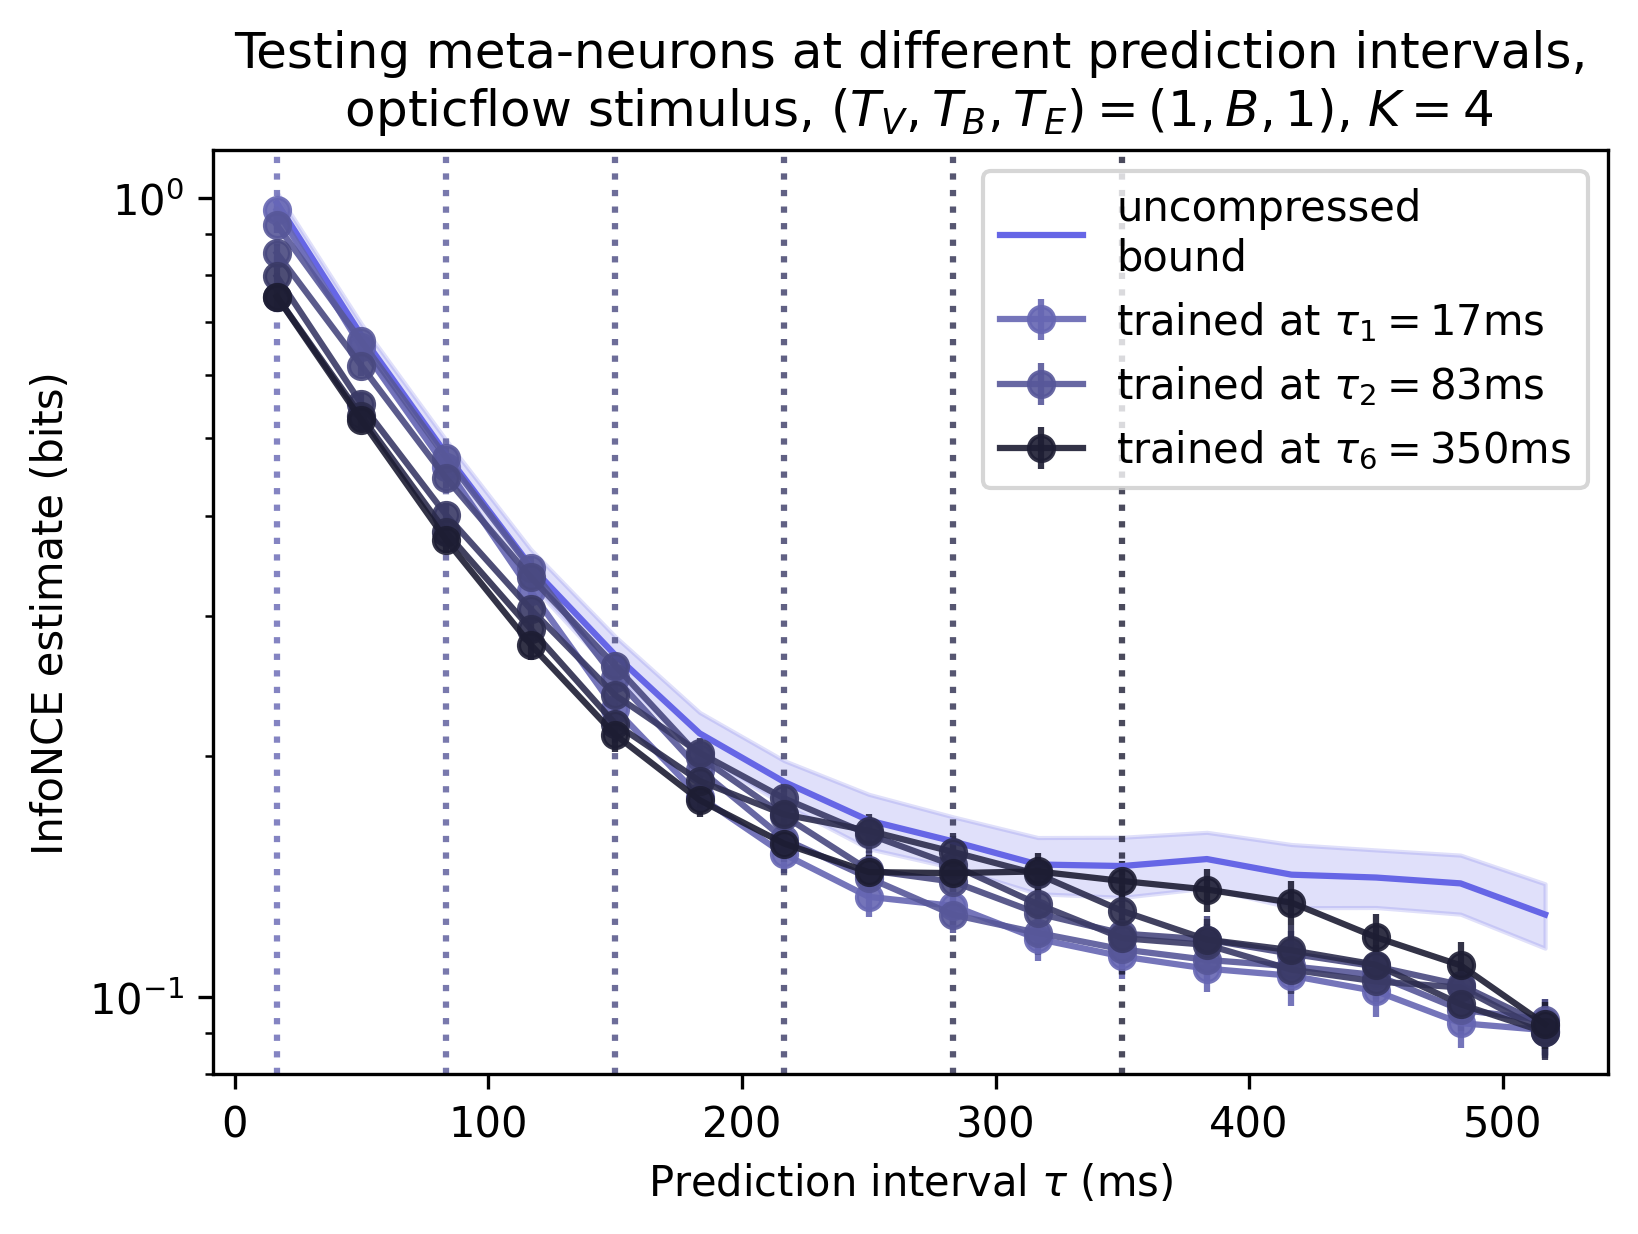

In [21]:
c1 = 0.4
c2 = 0.7
c3 = 0.9
alp1 = 0.4
alp2 = 0.9

N_reference_times = len(data.reference_times)
include_label = [0,1,N_reference_times-1]

binsize = 1000 / 60
x = (data.V_E_buffer_array + data.E_width) * binsize

fig, ax = plt.subplots(figsize=[6,4], dpi=300)
for i in range(N_reference_times):
    l = (N_reference_times - i + 1) / (N_reference_times + 1)
    cur_time = (data.reference_times[i] + E_width) * binsize
    if i in include_label:
        label_string = f"trained at $\\tau_{i + 1} = {cur_time:.0f}$ms"
    else:
        label_string=None
    
    plt.semilogy([],[])

    # plt.errorbar(x, average_train[i] / np.log(2), yerr=full_stdevs_train[i], marker='o', color=(c1*l,c2*l,c1*l,alp2), label=label_string)
    # plt.axvline(cur_time, linestyle=':', color=(c1*l,c2*l,c1*l,0.8))

    # plt.errorbar(x, average_test[i] / np.log(2), yerr=full_stdevs_test[i], marker='o', color=(c1*l,c1*l,c2*l,alp2))
    plt.errorbar(x, average_test[i] / np.log(2), yerr=full_stdevs_test[i], marker='o', color=(c1*l,c1*l,c2*l,alp2), label=label_string)
    plt.axvline(cur_time, linestyle=':', color=(c1*l,c1*l,c2*l,0.8))
    

plt.fill_between(x, (bound_average_test - bound_full_stdevs_test) / np.log(2), (bound_average_test + bound_full_stdevs_test) / np.log(2), color = (c1,c1,c3,0.2))
plt.plot(x, bound_average_test / np.log(2), color=(c1,c1,c3), label="uncompressed\nbound")

# plt.fill_between(x, (bound_average_train - bound_full_stdevs_train) / np.log(2), (bound_average_train + bound_full_stdevs_train) / np.log(2), color = (c1,c3,c1,0.2))
# plt.plot(x, bound_average_train / np.log(2), color=(c1,c3,c1))

# ax.set_ylim(0.06)
ax.set_ylabel("InfoNCE estimate (bits)")
ax.set_xlabel(r"Prediction interval $\tau$ (ms)")
ax.set_title(f"Testing meta-neurons at different prediction intervals,\n {stim} stimulus, $(T_V,T_B,T_E) = ({data.V_width},B,{data.E_width})$, $K={data.N_meta_neurons}$")
ax.legend()

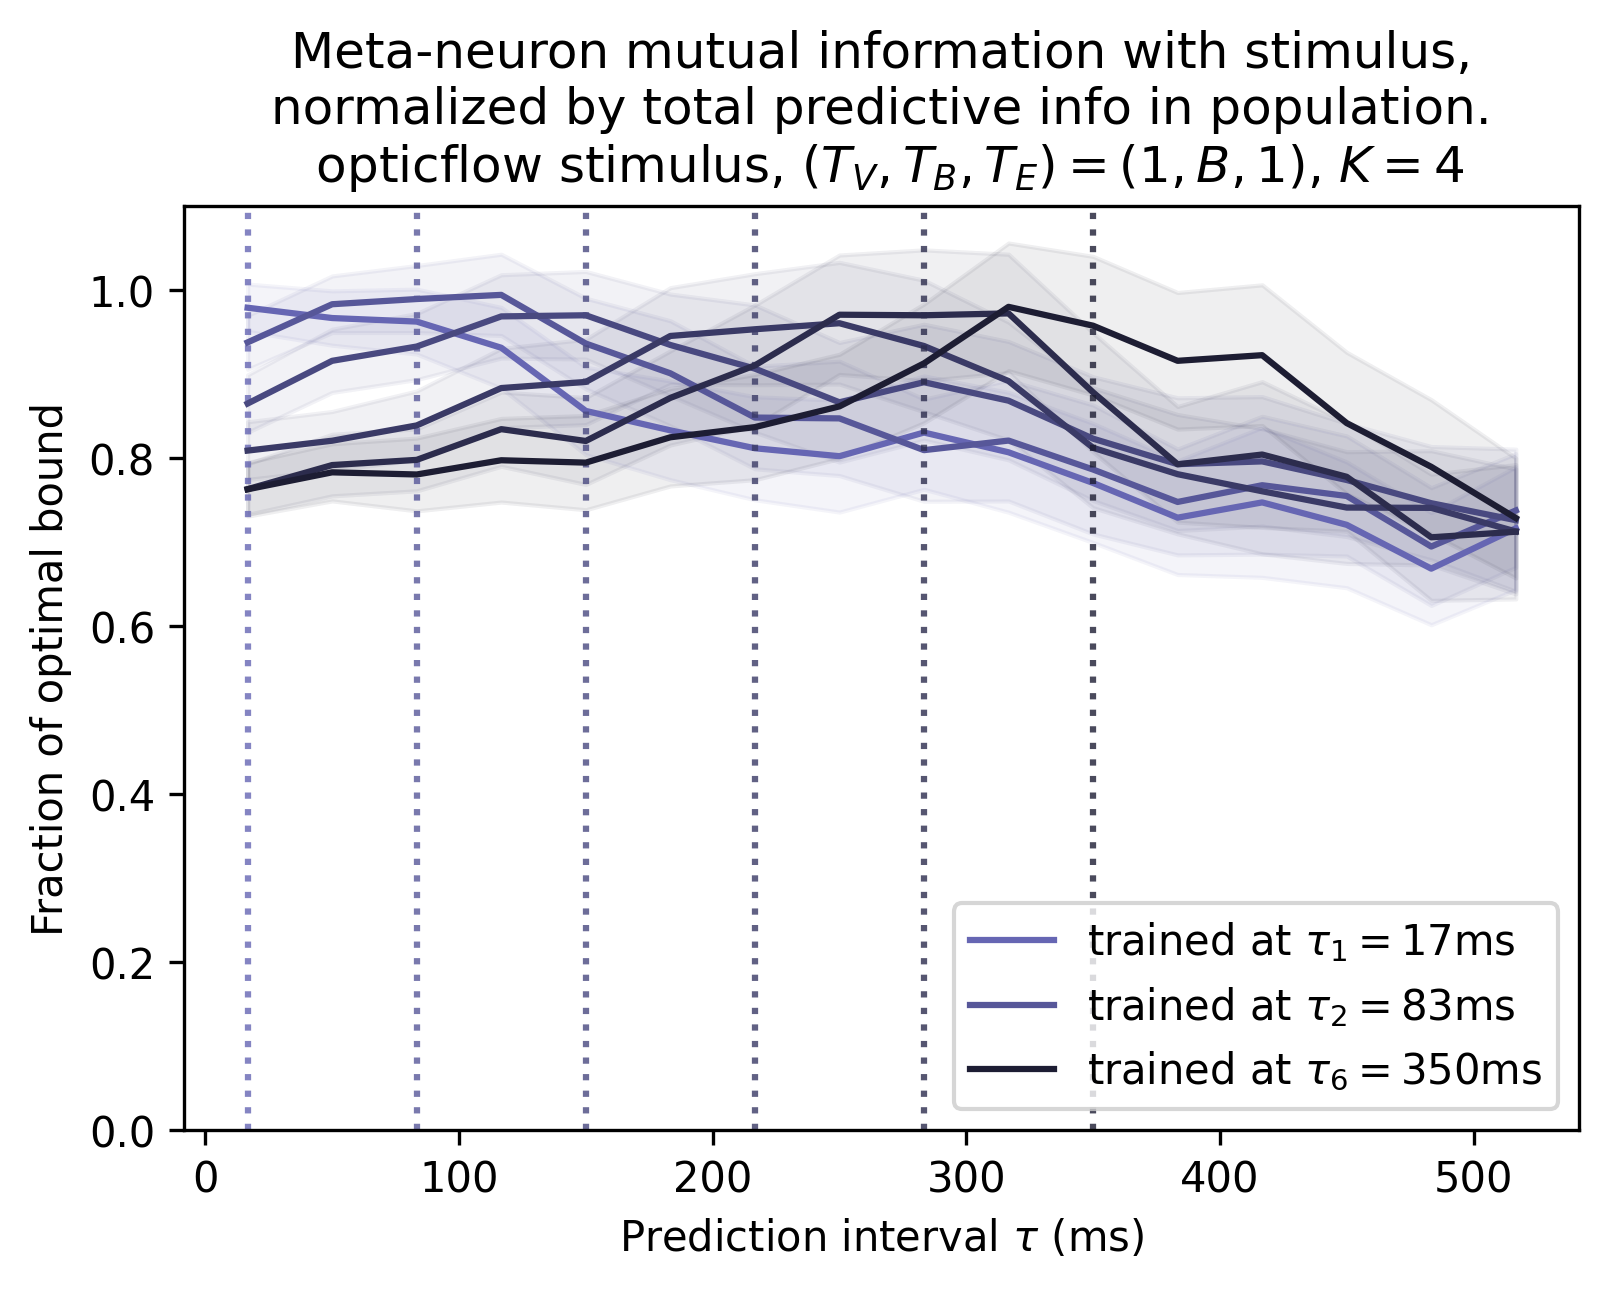

In [22]:
c1 = 0.4
c2 = 0.7
c3 = 0.9
alp1 = 0.4
alp2 = 0.9

N_reference_times = len(data.reference_times)
include_label = [0,1,N_reference_times-1]

binsize = 1000 / 60
x = (data.V_E_buffer_array + data.E_width) * binsize

fig, ax = plt.subplots(figsize=[6,4], dpi=300)
for i in range(N_reference_times):

    cur_time = (data.reference_times[i] + E_width) * binsize
    if i in include_label:
        label_string = f"trained at $\\tau_{i + 1} = {cur_time:.0f}$ms"
    else:
        label_string=None

    l = (N_reference_times - i + 1) / (N_reference_times + 1)
    # plt.semilogy([],[])
    
    # plt.errorbar(x, average_train[i] / bound_average_train, yerr=full_stdevs_train[i] / bound_average_train, marker='o', color=(c1*l,c2*l,c1*l,alp2))

    # plt.errorbar(x, average_test[i] / bound_average_test, yerr=full_stdevs_test[i] / bound_average_test, marker='o', color=(c1*l,c1*l,c2*l,alp2), label=label_string)
    
    # plt.axvline(cur_time, linestyle=':', color=(c1*l,c2*l,c1*l,0.8))
    plt.axvline(cur_time, linestyle=':', color=(c1*l,c1*l,c2*l,0.8))

    y = average_test[i] / bound_average_test
    diff = full_stdevs_test[i] / bound_average_test
    plt.fill_between(x, y-diff, y+diff, color=(c1*l,c1*l,c2*l,0.07))
    plt.plot(x, y, color=(c1*l,c1*l,c2*l), label=label_string)

    
# ax.set_ylim(0.06)
ax.set_ylim(0,1.1)
ax.set_ylabel("Fraction of optimal bound")
ax.set_xlabel(r"Prediction interval $\tau$ (ms)")
ax.set_title(f"Meta-neuron mutual information with stimulus,\nnormalized by total predictive info in population.\n {stim} stimulus, $(T_V,T_B,T_E) = ({data.V_width},B,{data.E_width})$, $K={data.N_meta_neurons}$")
ax.legend()